# 🏆 Best Model Configuration from notebook_ap.ipynb

Based on the experiments in `notebook_ap.ipynb`, this notebook creates a model with the best performing configuration.

**Configuration Source:** Experiment comparison results from notebook_ap.ipynb

In [209]:
# ========== IMPORTS ==========
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import sys
import os
import glob
from pathlib import Path
from sklearn.preprocessing import StandardScaler

# Add parent directory to path to access utils
sys.path.append(str(Path.cwd().parent))

# Import custom modules
from utils.simple_lds_loss import SimpleLDSLoss
from utils.reproducibility_utils import seed_everything
from utils.band_mapping import load_band_mapping
from utils.kaggle_metric import score
from utils.data_loading import load_data, load_test_data

# Load band mapping dictionary
shot_band_mapping = load_band_mapping()

print("✅ All imports successful")
print(f"✅ Loaded {len(shot_band_mapping)} sideslip band mappings")

✅ All imports successful
✅ Loaded 234 sideslip band mappings


In [210]:
# ========== SET SEED FOR REPRODUCIBILITY ==========
seed_everything(42)
print("✅ Seed set to 42")

✅ Seed set to 42


In [211]:
class RNN(nn.Module):
    """
    Recurrent Neural Network for sideSlip prediction with flexible initialization.
    """

    def __init__(self, 
                 input_size,          # Anzahl der Features
                 hidden_size=64,      # Größe der RNN-Units
                 num_layers=1,        # Anzahl der RNN-Layers
                 fc_units=64,         # Anzahl Units der Fully Connected Layer
                 output_size=1,       # Dimension des Outputs
                 activation_fct=nn.ReLU(), 
                 dropout=[0.2, 0, 0], # Dropouts: [input, nach RNN, nach FC]
                 rnn_type='RNN',      # 'RNN', 'LSTM' oder 'GRU'
                 rnn_nonlinearity='tanh'  # nur für RNN
                 ):
        super(RNN, self).__init__()

        self.dropout1 = nn.Dropout(dropout[0])
        self.dropout2 = nn.Dropout(dropout[1])
        self.dropout3 = nn.Dropout(dropout[2])
        self.activation_fct = activation_fct

        # RNN Layer
        if rnn_type.upper() == 'RNN':
            self.rnn_layer = nn.RNN(input_size=input_size,
                                    hidden_size=hidden_size,
                                    num_layers=num_layers,
                                    nonlinearity=rnn_nonlinearity,
                                    batch_first=True)
        elif rnn_type.upper() == 'LSTM':
            self.rnn_layer = nn.LSTM(input_size=input_size,
                                     hidden_size=hidden_size,
                                     num_layers=num_layers,
                                     batch_first=True)
        elif rnn_type.upper() == 'GRU':
            self.rnn_layer = nn.GRU(input_size=input_size,
                                    hidden_size=hidden_size,
                                    num_layers=num_layers,
                                    batch_first=True)
        else:
            raise ValueError(f"Unsupported rnn_type {rnn_type}")

        # Fully Connected Layer
        self.fc = nn.Linear(hidden_size, fc_units)
        self.output_layer = nn.Linear(fc_units, output_size)

    def forward(self, x):
        x = self.dropout1(x)
        x, _ = self.rnn_layer(x)  # output shape: (batch, seq_len, hidden_size)
        x = x[:, -1, :]            # nur letzter Zeitschritt
        x = self.dropout2(x)
        x = self.activation_fct(self.fc(x))
        x = self.dropout3(x)
        x = self.output_layer(x)
        return x


In [212]:
# ========== LOAD TRAINING AND VALIDATION DATA ==========
print("\n" + "="*80)
print("📂 LOADING DATA")
print("="*80)

# Pfad zu deinem Ordner
path = "../datasets_challenge/train"

# Alle CSV-Dateien im Ordner laden und sortieren
csv_files = sorted(glob.glob(os.path.join(path, "*.csv")))
print(f"Gefundene CSV-Dateien: {len(csv_files)}")

# Datei Nr. 15 → Index 14 (0-basiert)
val_index = 14
val_file = csv_files[val_index]

# Validierungs-Set laden
val_df = pd.read_csv(val_file)

# Trainings-Set: alle außer Nr. 15
train_files = [f for i, f in enumerate(csv_files) if i != val_index]
train_df = pd.concat([pd.read_csv(f) for f in train_files], ignore_index=True)

print("Validierungs-Datei:", val_file)
print("Trainings-Dateien:", len(train_files))

# ========== VELOCITY THRESHOLDING ==========
threshold_column = "vxCG"
threshold_value = 3.0

print(f"\nBefore threshold - Train: {len(train_df)} samples, Val: {len(val_df)} samples")

train_df = train_df[train_df[threshold_column] > threshold_value].reset_index(drop=True)
val_df = val_df[val_df[threshold_column] > threshold_value].reset_index(drop=True)

print(f"After threshold  - Train: {len(train_df)} samples, Val: {len(val_df)} samples")

# Spalten
drop_columns = ["sideSlip", "vyCG", "time", "longitude", "latitude"]
feature_columns = [col for col in train_df.columns if col not in drop_columns]
target_column = "sideSlip"

X_train = train_df[feature_columns].values
y_train = train_df[target_column].values.reshape(-1, 1)

X_val = val_df[feature_columns].values
y_val = val_df[target_column].values.reshape(-1, 1)

# Standardization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

# Sequence parameters
sequence_length = 20
batch_size = 512

# Create sequences function
def create_sequences(X, y, seq_len):
    sequences = []
    targets = []
    for i in range(len(X) - seq_len):
        seq_x = X[i:i+seq_len]
        seq_y = y[i+seq_len]
        sequences.append(seq_x)
        targets.append(seq_y)
    return np.array(sequences), np.array(targets)

# Train sequences
X_train_seq, y_train_seq = create_sequences(X_train, y_train, sequence_length)

# Val sequences
X_val_seq, y_val_seq = create_sequences(X_val, y_val, sequence_length)

# TensorDatasets
train_dataset = TensorDataset(torch.tensor(X_train_seq, dtype=torch.float32),
                              torch.tensor(y_train_seq, dtype=torch.float32))

val_dataset = TensorDataset(torch.tensor(X_val_seq, dtype=torch.float32),
                            torch.tensor(y_val_seq, dtype=torch.float32))

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

print(f"\n✅ Data loaded successfully")
print(f"   Training sequences: {len(X_train_seq):,}")
print(f"   Validation sequences: {len(X_val_seq):,}")
print(f"   Features: {X_train_seq.shape[2]}")
print(f"   Sequence length: {X_train_seq.shape[1]}")


📂 LOADING DATA
Gefundene CSV-Dateien: 22
Validierungs-Datei: ../datasets_challenge/train\train_part_015.csv
Trainings-Dateien: 21

Before threshold - Train: 265541 samples, Val: 9685 samples
After threshold  - Train: 129588 samples, Val: 8347 samples
Validierungs-Datei: ../datasets_challenge/train\train_part_015.csv
Trainings-Dateien: 21

Before threshold - Train: 265541 samples, Val: 9685 samples
After threshold  - Train: 129588 samples, Val: 8347 samples

✅ Data loaded successfully
   Training sequences: 129,568
   Validation sequences: 8,327
   Features: 22
   Sequence length: 20

✅ Data loaded successfully
   Training sequences: 129,568
   Validation sequences: 8,327
   Features: 22
   Sequence length: 20


In [213]:
# ========== BEST MODEL CONFIGURATION ==========
print("\n" + "="*80)
print("🏆 BEST MODEL CONFIGURATION")
print("="*80)

device = "cuda" if torch.cuda.is_available() else "cpu"

# Architecture parameters
hidden_size_best = 32
fc_units_best = 32
num_layers_best = 2
dropout_probs_best = [0.2, 0.3, 0.2]

# Training parameters
lr = 0.0005
weight_decay = 1e-4

# Scheduler parameters
scheduler_mode = 'min'
scheduler_factor = 0.5
scheduler_patience = 3
scheduler_min_lr = 1e-6

# Training configuration
num_epochs = 50
early_stop_thresh = 10

# Loss strategy
use_lds_best = True

print(f"\n🏗️  Architecture:")
print(f"   - RNN Type: LSTM")
print(f"   - Hidden Size: {hidden_size_best}")
print(f"   - FC Units: {fc_units_best}")
print(f"   - Num Layers: {num_layers_best}")
print(f"   - Dropout: {dropout_probs_best}")
print(f"\n⚙️  Training:")
print(f"   - Learning Rate: {lr}")
print(f"   - Weight Decay: {weight_decay}")
print(f"   - Early Stopping: {early_stop_thresh} epochs")
print(f"\n🎯 Strategy:")
print(f"   - Use LDS: {use_lds_best}")


🏆 BEST MODEL CONFIGURATION

🏗️  Architecture:
   - RNN Type: LSTM
   - Hidden Size: 32
   - FC Units: 32
   - Num Layers: 2
   - Dropout: [0.2, 0.3, 0.2]

⚙️  Training:
   - Learning Rate: 0.0005
   - Weight Decay: 0.0001
   - Early Stopping: 10 epochs

🎯 Strategy:
   - Use LDS: True


In [214]:
# ========== CREATE MODEL ==========
print("\n" + "="*80)
print("🔧 INSTANTIATING MODEL")
print("="*80)

# Create model
model_best = RNN(
    input_size=X_train_seq.shape[2],  # Number of features
    hidden_size=hidden_size_best,
    num_layers=num_layers_best,
    fc_units=fc_units_best,
    dropout=dropout_probs_best,
    rnn_type='LSTM',
    output_size=1
).to(device)

print(f"✅ Model created: LSTM({hidden_size_best}/{fc_units_best})")
print(f"   Input features: {X_train_seq.shape[2]}")
print(f"   Parameters: {sum(p.numel() for p in model_best.parameters()):,}")
lds_ks = 9
lds_sigma = 4.0
# Create loss function
if use_lds_best:
    criterion_best = SimpleLDSLoss(
        train_targets=y_train_seq.flatten(),
        base='smoothl1',
        smoothl1_beta=0.1,
        reweight='sqrt_inv',    # Bewährte Konfiguration
        lds=True,
        lds_kernel='gaussian',
        lds_ks=lds_ks,               # Original beste Werte
        lds_sigma=lds_sigma,          # Original beste Werte
        num_bins=100
    )
    print(f"✅ LDS Loss created with sqrt_inv reweighting (ks=9, sigma=4.0) - ORIGINAL BEST")
else:
    criterion_best = nn.SmoothL1Loss(beta=0.1)
    print(f"✅ SmoothL1Loss created")

# Create optimizer
optimizer_best = torch.optim.Adam(
    model_best.parameters(), 
    lr=lr, 
    weight_decay=weight_decay
)

# Create scheduler
scheduler_best = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_best,
    mode=scheduler_mode,
    factor=scheduler_factor,
    patience=scheduler_patience,
    min_lr=scheduler_min_lr
)

print(f"✅ Optimizer and Scheduler created")
print(f"\n🎯 Ready to train!")


🔧 INSTANTIATING MODEL
✅ Model created: LSTM(32/32)
   Input features: 22
   Parameters: 16,705
✅ LDS enabled: gaussian kernel (ks=9, sigma=4.0)

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.034, 5.368]
Weight mean: 1.000 (normalized to 1.0)

✅ LDS Loss created with sqrt_inv reweighting (ks=9, sigma=4.0) - ORIGINAL BEST
✅ Optimizer and Scheduler created

🎯 Ready to train!


In [215]:
# ========== TRAINING LOOP ==========
print("\n" + "="*80)
print("🚀 STARTING TRAINING")
print("="*80)

# Reset seed before training
seed_everything(42)

best_val_loss = np.inf
best_epoch = -1
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    # Training phase
    model_best.train()
    running_loss = 0.0
    
    for step, (x, y) in enumerate(train_loader):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        
        optimizer_best.zero_grad()
        pred = model_best(X)
        loss = criterion_best(pred, y)
        running_loss += loss.item()
        loss.backward()
        optimizer_best.step()
    
    avg_train_loss = running_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    
    # Validation phase
    model_best.eval()
    running_val_loss = 0.0
    
    with torch.no_grad():
        for x, y in val_loader:
            X, y = x.to(device), y.to(device).reshape([len(y), 1])
            pred = model_best(X)
            val_loss = criterion_best(pred, y)
            running_val_loss += val_loss.item()
    
    avg_val_loss = running_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)
    
    # Update scheduler
    scheduler_best.step(avg_val_loss)
    
    # Check for improvement
    status = f"Epoch {epoch+1}/{num_epochs} | Train: {avg_train_loss:.5f} | Val: {avg_val_loss:.5f}"
    
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_epoch = epoch
        torch.save({
            'epoch': epoch,
            'model_state_dict': model_best.state_dict(),
            'optimizer_state_dict': optimizer_best.state_dict(),
            'loss': best_val_loss
        }, 'best_model_v2.pth')
        status += f" → Best!"
    elif epoch - best_epoch > early_stop_thresh:
        status += f" → Early stopping (best epoch: {best_epoch+1})"
        print(status)
        break
    
    print(status)

# Load best model
if best_epoch != -1:
    checkpoint = torch.load('best_model_v2.pth', weights_only=True)
    model_best.load_state_dict(checkpoint['model_state_dict'])
    print(f"\n✅ Best model loaded from epoch {best_epoch+1}")


🚀 STARTING TRAINING
Epoch 1/50 | Train: 0.07287 | Val: 0.01664 → Best!
Epoch 1/50 | Train: 0.07287 | Val: 0.01664 → Best!
Epoch 2/50 | Train: 0.03690 | Val: 0.01094 → Best!
Epoch 2/50 | Train: 0.03690 | Val: 0.01094 → Best!
Epoch 3/50 | Train: 0.03301 | Val: 0.01339
Epoch 3/50 | Train: 0.03301 | Val: 0.01339
Epoch 4/50 | Train: 0.03165 | Val: 0.00893 → Best!
Epoch 4/50 | Train: 0.03165 | Val: 0.00893 → Best!
Epoch 5/50 | Train: 0.03019 | Val: 0.00984
Epoch 5/50 | Train: 0.03019 | Val: 0.00984
Epoch 6/50 | Train: 0.02866 | Val: 0.00919
Epoch 6/50 | Train: 0.02866 | Val: 0.00919
Epoch 7/50 | Train: 0.02855 | Val: 0.00985
Epoch 7/50 | Train: 0.02855 | Val: 0.00985
Epoch 8/50 | Train: 0.02833 | Val: 0.00964
Epoch 8/50 | Train: 0.02833 | Val: 0.00964
Epoch 9/50 | Train: 0.02718 | Val: 0.01148
Epoch 9/50 | Train: 0.02718 | Val: 0.01148
Epoch 10/50 | Train: 0.02698 | Val: 0.01172
Epoch 10/50 | Train: 0.02698 | Val: 0.01172
Epoch 11/50 | Train: 0.02709 | Val: 0.01158
Epoch 11/50 | Train: 0.02

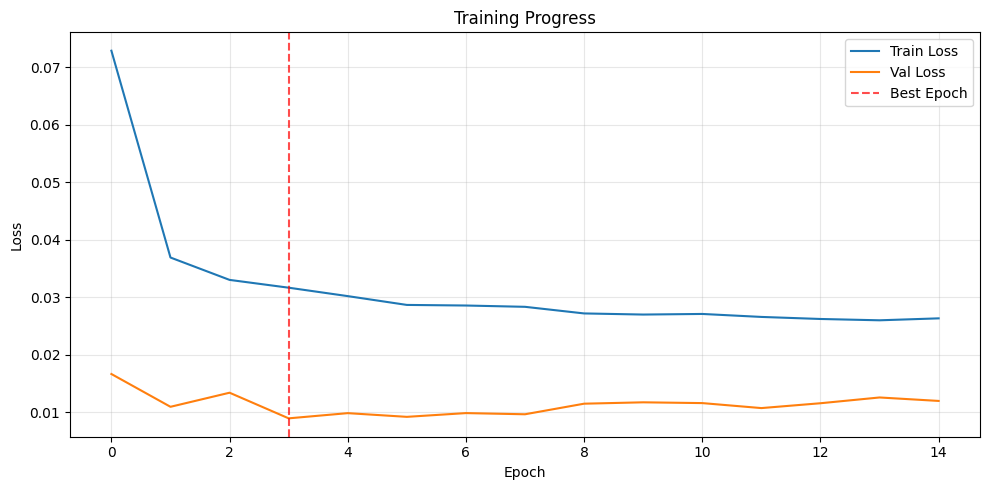


📊 Training Summary:
   Best Epoch: 4
   Best Val Loss: 0.00893
   Total Epochs: 15


In [216]:
# ========== VISUALIZE TRAINING ==========
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(train_losses, label='Train Loss')
ax.plot(val_losses, label='Val Loss')
ax.axvline(x=best_epoch, color='red', linestyle='--', label='Best Epoch', alpha=0.7)
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Training Progress')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n📊 Training Summary:")
print(f"   Best Epoch: {best_epoch+1}")
print(f"   Best Val Loss: {best_val_loss:.5f}")
print(f"   Total Epochs: {len(train_losses)}")

In [217]:
# ========== EVALUATE ON VALIDATION SET ==========
print("\n" + "="*80)
print("📊 VALIDATION SET EVALUATION")
print("="*80)

model_best.eval()
val_preds = []
val_gts = []

with torch.no_grad():
    for x, y in val_loader:
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        pred = model_best(X)
        val_preds.append(pred.cpu().numpy().flatten())
        val_gts.append(y.cpu().numpy().flatten())

val_gts = np.concatenate(val_gts)
val_preds = np.concatenate(val_preds)

# Create DataFrames for score calculation with band mapping
# Round ground truth to 1 decimal place to match shot_band_mapping keys
val_gts_rounded = np.round(val_gts, 1)

# Map each ground truth value to its band
bands = [shot_band_mapping.get(gt, 'unknown') for gt in val_gts_rounded]

# Create solution DataFrame (ground truth with bands)
val_gt_df = pd.DataFrame({
    'id': range(len(val_gts)),
    'ground_truth_sideslip': val_gts,
    'band': bands
})

# Create submission DataFrame (predictions)
val_preds_df = pd.DataFrame({
    'id': range(len(val_preds)),
    'predicted_sideslip': val_preds
})

# Calculate scores by shot band
val_result = score(val_gt_df, val_preds_df, 'id')

print("\n📈 Validation Scores:")
print(f"   Many-Shot MAE:   {val_result['many']:.3f}°")
print(f"   Medium-Shot MAE: {val_result['medium']:.3f}°")
print(f"   Few-Shot MAE:    {val_result['few']:.3f}°")

# Check Kaggle constraint
if val_result['many'] > 0.2:
    print(f"\n⚠️  WARNING: Many-Shot MAE ({val_result['many']:.3f}°) exceeds Kaggle constraint (0.2°)")
else:
    print(f"\n✅ Many-Shot MAE satisfies Kaggle constraint (< 0.2°)")


📊 VALIDATION SET EVALUATION

📈 Validation Scores:
   Many-Shot MAE:   0.153°
   Medium-Shot MAE: 0.404°
   Few-Shot MAE:    0.419°

✅ Many-Shot MAE satisfies Kaggle constraint (< 0.2°)


In [218]:
# ========== LOAD TEST DATA USING PIPELINE ==========
print("\n" + "="*80)
print("🔮 GENERATING TEST PREDICTIONS")
print("="*80)

# Load test data using pipeline (exact same as notebook_ap.ipynb)
print("Loading test data using pipeline...")

test_path = "../datasets_challenge/test"

# Create pipeline from training parameters
print("Creating pipeline from training data...")

train_dataloader_tmp, val_dataloader_tmp, pipeline = load_data(
    train_path="../datasets_challenge/train",
    train_ratio=0.95,  # Same as training split (21/22 files)
    batchsize=batch_size,
    columns_to_drop=drop_columns,
    sequence_length=sequence_length,
    threshold=True,
    threshold_value=threshold_value,
    threshold_column=threshold_column,
    target=target_column,
    scaling=True,
    seed=42
)

print(f"✓ Pipeline created from training data")

# Use pipeline to load test data
test_loader = load_test_data(
    test_path=test_path,
    batchsize=batch_size,
    pipeline=pipeline,
    load_anonymized_data=True  # Test data has no real sideSlip/vyCG
)

# Count samples in test_loader
test_sample_count = 0
for batch_x, batch_y in test_loader:
    test_sample_count += len(batch_x)

print(f"\n📊 Test Data Statistics:")
print(f"   Total test samples: {test_sample_count:,}")
print(f"   Expected (Kaggle): 49,328")
if test_sample_count == 49328:
    print(f"   ✅ MATCH! Using pipeline gives correct count")
else:
    print(f"   ⚠️  Got {test_sample_count:,} instead of 49,328")

# Store test IDs
test_sequence_ids = np.arange(test_sample_count)

# ========== GENERATE TEST PREDICTIONS ==========
print("\nGenerating predictions on test set...")

model_best.eval()
test_preds = []

with torch.no_grad():
    for step, (x, _) in enumerate(test_loader):
        X = x.to(device)
        pred = model_best(X)
        test_preds.append(pred.reshape(-1).cpu().numpy())

test_preds = np.concatenate(test_preds)

print(f"\n✓ Generated {len(test_preds):,} predictions")
print(f"✓ Prediction range: [{test_preds.min():.2f}°, {test_preds.max():.2f}°]")
print(f"✓ Prediction mean: {test_preds.mean():.2f}°, std: {test_preds.std():.2f}°")

if len(test_preds) == 49328:
    print(f"✅ Perfect! Got exactly 49,328 predictions (matches Kaggle requirement)")
else:
    print(f"⚠️  Got {len(test_preds):,} predictions (expected 49,328)")

# ========== SAVE PREDICTIONS FOR SUBMISSION ==========
y_pred_final = pd.DataFrame({
    "id": test_sequence_ids,
    "predicted_sideslip": test_preds
})

print(f"\n📊 Submission Statistics:")
print(f"  - Predictions generated: {len(test_preds):,}")
print(f"  - ID range: [{y_pred_final['id'].min()}, {y_pred_final['id'].max()}]")
print(f"  - Expected count: 49,328")

if len(y_pred_final) == 49328:
    print(f"\n✅ PERFECT! Exactly 49,328 samples (matches Kaggle requirement)")
else:
    print(f"\n⚠️  Got {len(y_pred_final):,} samples (expected 49,328)")

# Save to CSV
output_file = "predictions_apv2_best.csv"
y_pred_final.to_csv(output_file, index=False)

print(f"\n✓ Predictions saved to '{output_file}'")
print(f"✓ Using pipeline-based processing (same as notebook_ap.ipynb)")
print(f"✓ Ready for Kaggle submission!")
print(f"\n📋 File preview:")
print(y_pred_final.head(10))


🔮 GENERATING TEST PREDICTIONS
Loading test data using pipeline...
Creating pipeline from training data...
../datasets_challenge/train\train_part_001.csv
../datasets_challenge/train\train_part_002.csv
../datasets_challenge/train\train_part_003.csv
../datasets_challenge/train\train_part_004.csv
../datasets_challenge/train\train_part_005.csv
../datasets_challenge/train\train_part_006.csv
../datasets_challenge/train\train_part_007.csv
../datasets_challenge/train\train_part_004.csv
../datasets_challenge/train\train_part_005.csv
../datasets_challenge/train\train_part_006.csv
../datasets_challenge/train\train_part_007.csv
../datasets_challenge/train\train_part_008.csv
../datasets_challenge/train\train_part_009.csv
../datasets_challenge/train\train_part_008.csv
../datasets_challenge/train\train_part_009.csv
../datasets_challenge/train\train_part_010.csv
../datasets_challenge/train\train_part_011.csv
../datasets_challenge/train\train_part_012.csv
../datasets_challenge/train\train_part_010.csv


c:\Repos\mait_g2_drift_challenge\.venv\Lib\site-packages\sklearn\pipeline.py:61: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(



📊 Test Data Statistics:
   Total test samples: 49,328
   Expected (Kaggle): 49,328
   ✅ MATCH! Using pipeline gives correct count

Generating predictions on test set...

✓ Generated 49,328 predictions
✓ Prediction range: [-6.79°, 8.49°]
✓ Prediction mean: -0.00°, std: 1.38°
✅ Perfect! Got exactly 49,328 predictions (matches Kaggle requirement)

📊 Submission Statistics:
  - Predictions generated: 49,328
  - ID range: [0, 49327]
  - Expected count: 49,328

✅ PERFECT! Exactly 49,328 samples (matches Kaggle requirement)

✓ Predictions saved to 'predictions_apv2_best.csv'
✓ Using pipeline-based processing (same as notebook_ap.ipynb)
✓ Ready for Kaggle submission!

📋 File preview:
   id  predicted_sideslip
0   0            0.040953
1   1            0.046207
2   2            0.044901
3   3            0.048340
4   4            0.044971
5   5            0.009041
6   6           -0.028677
7   7           -0.044525
8   8           -0.034341
9   9           -0.017719

✓ Generated 49,328 predictio